# Deep Learning Group Project: Tiny ImageNet

## Index

1. Exploratory Data Analysis 
2. Data preparation and image preprocessing
3. Train, validation, and test split
4. Model development (including a pre-trained transfer-learning approach)
5. Experimental setup, training, and intermediate experiments
6. Model evaluation and comparison
7. Error analysis
8. Conclusions and references / acknowledgements

## Setup and Libraries

In [1]:
# Standard library imports
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
import hashlib
from pathlib import Path

# Third-party libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image


# 1. Exploratory Data Analysis 



## 1.1 Load the labels and locate the images

The project data is expected in `Tiny_ImageNet_Project_2026_Students/`, next to this notebook. If your files are elsewhere, update `DATA_DIR` below.

In [2]:
DATA_DIR = Path("Tiny_ImageNet_Project_2026_Students")
LABELS_PATH = DATA_DIR / "labels.csv"
IMAGES_DIR = DATA_DIR / "images"

labels = pd.read_csv(LABELS_PATH)
image_paths = {path.name: path for path in IMAGES_DIR.iterdir()}

print(f"Label rows: {len(labels):,}")
print(f"Image files: {len(image_paths):,}")
display(labels.head())

Label rows: 60,000
Image files: 60,000


,filename,class_id,description
0,image_000001.JPEG,n03042490,cliff dwelling
1,image_000002.JPEG,n02793495,barn
2,image_000003.JPEG,n02793495,barn
3,image_000004.JPEG,n02793495,barn
4,image_000005.JPEG,n02793495,barn


## 1.2 Check label-table quality

Check required columns, missing values, duplicate filenames, and whether each class ID maps to exactly one description.

In [3]:
required_columns = {"filename", "class_id", "description"}
missing_columns = required_columns - set(labels.columns)
if missing_columns:
    raise ValueError(f"Missing required columns: {sorted(missing_columns)}")

print("Missing values by column:")
display(labels[list(required_columns)].isna().sum().rename("missing_count").to_frame())
print(f"Duplicate filename rows: {labels['filename'].duplicated(keep=False).sum():,}")
class_description_counts = labels.groupby("class_id")["description"].nunique()
inconsistent_classes = class_description_counts[class_description_counts > 1]
print(f"Classes with multiple descriptions: {len(inconsistent_classes)}")
print(f"Unique classes: {labels['class_id'].nunique():,}")

Missing values by column:


,missing_count
filename,0
class_id,0
description,0


Duplicate filename rows: 0
Classes with multiple descriptions: 0
Unique classes: 200


## 1.3 Compare label references with files on disk

Do not silently discard missing files. Quantify both missing label references and image files without a label before deciding how to prepare the dataset.

In [4]:
label_filenames = set(labels["filename"].dropna().astype(str))
disk_filenames = set(image_paths)
missing_images = sorted(label_filenames - disk_filenames)
unlabeled_images = sorted(disk_filenames - label_filenames)

print(f"Label rows referencing files not found: {len(missing_images):,}")
print(f"Image files without a label row: {len(unlabeled_images):,}")
print("Examples of missing files:", missing_images[:10])
print("Examples of unlabeled files:", unlabeled_images[:10])

Label rows referencing files not found: 0
Image files without a label row: 0
Examples of missing files: []
Examples of unlabeled files: []


## 1.4 Inspect class balance

Report label counts per class, including labels whose image file is absent. The next cell also shows counts for files that are available.

In [5]:
class_counts = labels.groupby(["class_id", "description"], dropna=False).size().rename("label_rows")
available_labels = labels[labels["filename"].astype(str).isin(disk_filenames)]
unambiguous_labels = available_labels[~available_labels["filename"].duplicated(keep=False)]
available_class_counts = (
    unambiguous_labels.groupby(["class_id", "description"], dropna=False)
    .size()
    .rename("unambiguous_available_images")
)
class_summary = pd.concat([class_counts, available_class_counts], axis=1).fillna(0).astype(int)
display(class_summary.describe().T)
display(class_summary.sort_values("unambiguous_available_images").head(10))

,count,mean,std,min,25%,50%,75%,max
label_rows,200.0,300.0,152.723582,108.0,177.0,273.5,395.75,549.0
unambiguous_available_images,200.0,300.0,152.723582,108.0,177.0,273.5,395.75,549.0


,,label_rows,unambiguous_available_images
class_id,description,,
n07873807,"pizza, pizza pie",108,108
n07753592,banana,108,108
n02106662,"German shepherd, German shepherd dog, German police dog, alsatian",109,109
n01768244,trilobite,112,112
n03649909,"lawn mower, mower",113,113
n02977058,"cash machine, cash dispenser, automated teller machine, automatic teller machine, automated teller, automatic teller, ATM",114,114
n03930313,"picket fence, paling",114,114
n02410509,bison,114,114
n02666196,abacus,114,114


## 1.5 Review representative images

Visually inspect a small random sample before choosing image preprocessing. The sample is restricted to files with labels.

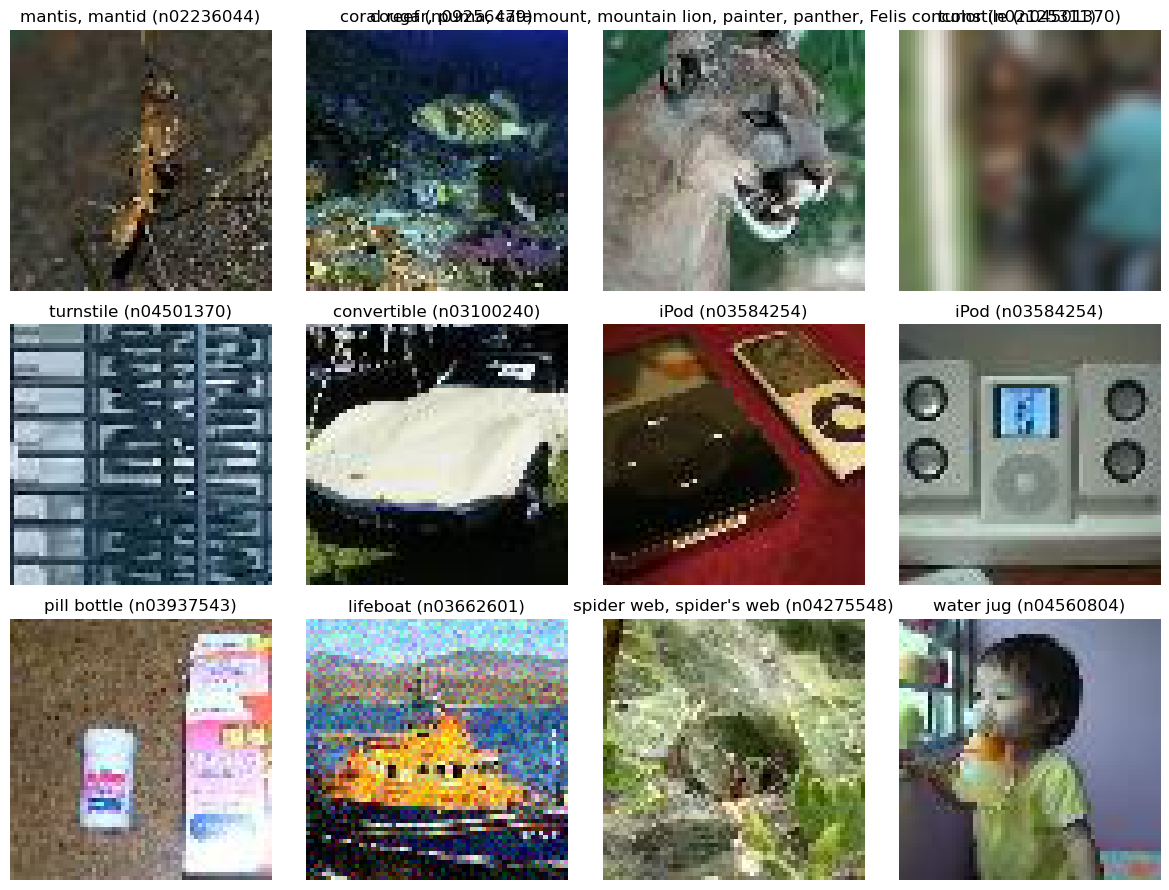

In [6]:
sample = unambiguous_labels.sample(n=min(12, len(unambiguous_labels)), random_state=42)
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for ax, (_, row) in zip(axes.flat, sample.iterrows()):
    with Image.open(image_paths[str(row["filename"])]) as image:
        ax.imshow(image.convert("RGB"))
    ax.set_title(f"{row['description']} ({row['class_id']})")
    ax.axis("off")
for ax in axes.flat[len(sample):]:
    ax.axis("off")
plt.tight_layout()
plt.show()


## 1.6 Check image dimensions and file integrity

Verify that all images are readable, check if all resolutions are 64x64.


In [13]:
def inspect_image(fn):
    try:
        with Image.open(IMAGES_DIR / fn) as img:
            return (img.size, img.mode, True)
    except Exception:
        return (None, None, False)

with ThreadPoolExecutor(max_workers=16) as pool:
    img_info = list(pool.map(inspect_image, labels['filename']))
    
sizes = Counter(info[0] for info in img_info)
corrupt_count = sum(1 for info in img_info if not info[2])


print(f"Total images checked: {len(img_info):,}")
print(f"Corrupted or unreadable images: {corrupt_count}")
print(f"Image resolutions found: {dict(sizes)}")


Total images checked: 60,000
Corrupted or unreadable images: 0
Image resolutions found: {(64, 64): 60000}


## 1.7 Audit duplicate images and conflicting labels (Label Inconsistencies)

Check for identical image files across the dataset using MD5 hashing, and identify images that share identical pixels but carry conflicting labels (annotation errors / label noise).

Total duplicate image instances: 12
Duplicate images with CONFLICTING labels: 12

Identical images with conflicting class labels:


,filename,class_id,description,hash
593,image_000594.JPEG,n03891332,parking meter,0be47e31eb042f4b1ef14a25c178d35b
13623,image_013624.JPEG,n07747607,orange,0be47e31eb042f4b1ef14a25c178d35b
33613,image_033614.JPEG,n01984695,"spiny lobster, langouste, rock lobster, crawfi...",5dcde42b577674f21c6016936bed8dd2
40382,image_040383.JPEG,n01983481,"American lobster, Northern lobster, Maine lobs...",5dcde42b577674f21c6016936bed8dd2
1090,image_001091.JPEG,n07749582,lemon,7444ddabb30a9dafc6f7a3158e1bea8e
59133,image_059134.JPEG,n07753592,banana,7444ddabb30a9dafc6f7a3158e1bea8e
27766,image_027767.JPEG,n03404251,fur coat,78ff74ea6c268345429555e5988a9106
47291,image_047292.JPEG,n02988304,CD player,78ff74ea6c268345429555e5988a9106
11907,image_011908.JPEG,n01950731,"sea slug, nudibranch",99570138645ac02e18369c41b8beab4a
30312,image_030313.JPEG,n01945685,slug,99570138645ac02e18369c41b8beab4a


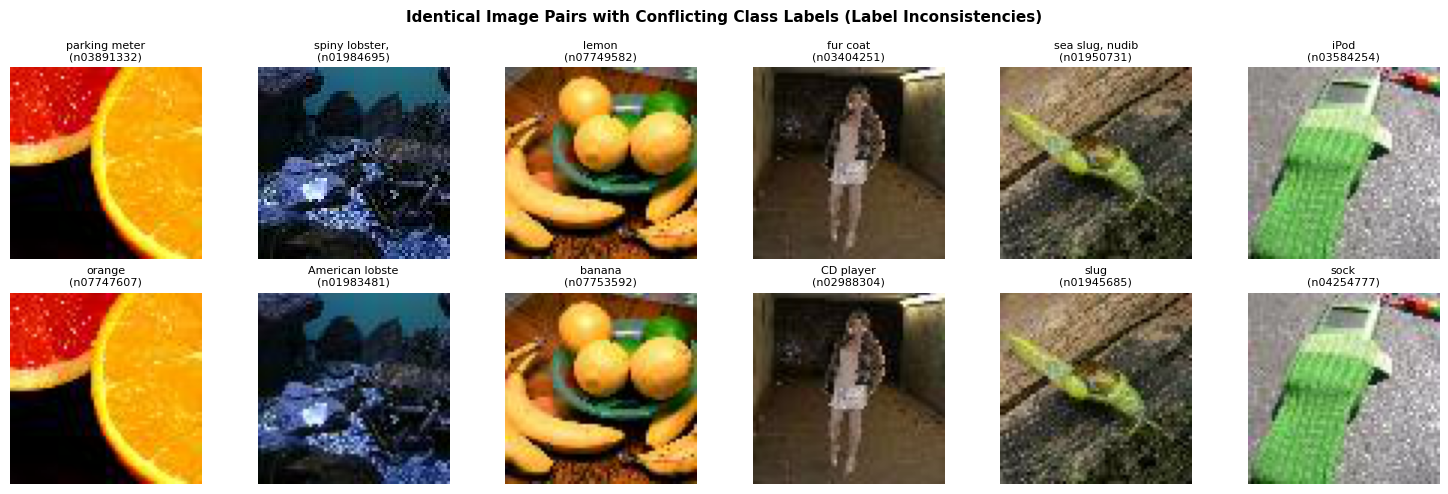

In [8]:
def get_hash(fn):
    with open(IMAGES_DIR / fn, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()

with ThreadPoolExecutor(max_workers=16) as pool:
    labels['hash'] = list(pool.map(get_hash, labels['filename']))

duplicates = labels.groupby('hash').filter(lambda g: len(g) > 1)
conflicts = duplicates.groupby('hash').filter(lambda g: g['class_id'].nunique() > 1)

print(f"Total duplicate image instances: {len(duplicates)}")
print(f"Duplicate images with CONFLICTING labels: {len(conflicts)}")

if len(conflicts) > 0:
    print("\nIdentical images with conflicting class labels:")
    display(conflicts.sort_values('hash')[['filename', 'class_id', 'description', 'hash']])

# Visualize the 6 conflicting duplicate pairs side-by-side
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for i, (_, row) in enumerate(conflicts.sort_values('hash').iterrows()):
    ax = axes[i % 2, i // 2]
    with Image.open(IMAGES_DIR / row['filename']) as img:
        ax.imshow(img.convert('RGB'))
    ax.set_title(f"{row['description'][:15]}\n({row['class_id']})", fontsize=8)
    ax.axis('off')
fig.suptitle("Identical Image Pairs with Conflicting Class Labels (Label Inconsistencies)", fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

## 1.8 Visualize class distribution

Inspect class representation across all 200 classes and compute the imbalance ratio.


Minimum class count: 108
Maximum class count: 549
Imbalance ratio (max / min): 5.08x


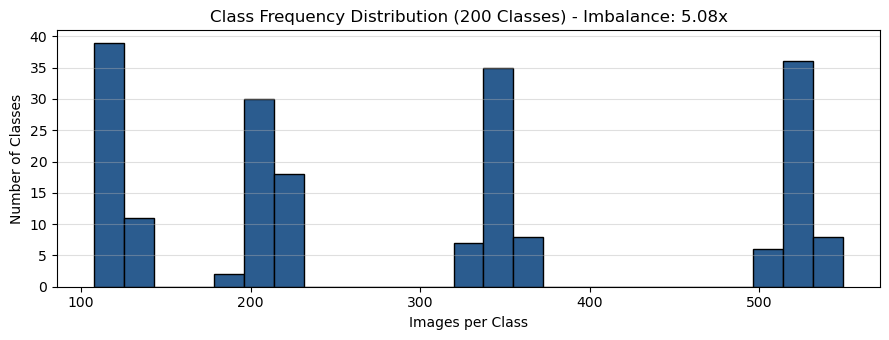

In [9]:
class_freq = labels['class_id'].value_counts()
min_count, max_count = class_freq.min(), class_freq.max()
imbalance_ratio = max_count / min_count

print(f"Minimum class count: {min_count}")
print(f"Maximum class count: {max_count}")
print(f"Imbalance ratio (max / min): {imbalance_ratio:.2f}x")

plt.figure(figsize=(9, 3.5))
plt.hist(class_freq, bins=25, edgecolor='black', color='#2b5c8f')
plt.title(f"Class Frequency Distribution (200 Classes) - Imbalance: {imbalance_ratio:.2f}x")
plt.xlabel("Images per Class")
plt.ylabel("Number of Classes")
plt.grid(axis='y', alpha=0.4)
plt.tight_layout()
plt.show()


## 1.9 Outliers

Analyze visual and structural image outliers across the dataset:
1. **Color modality outliers**: Single-channel grayscale (`'L'`) images within a standard RGB dataset.
2. **Statistical pixel intensity outliers**: Extremely dark, over-exposed, or low-contrast (flat) images.

### 1.9.1 Color Modality Outliers (Grayscale vs. RGB)

In computer vision models expecting standard 3-channel RGB inputs, single-channel grayscale (`'L'`) images act as structural outliers. Passing 1-channel images directly into a convolutional network causes tensor shape mismatch errors. Here we quantify and visualize representative grayscale outliers to confirm the preprocessing decision to enforce `.convert('RGB')` during data loading.

Color mode distribution:
color_mode
RGB    59194
L        806
Name: count, dtype: int64


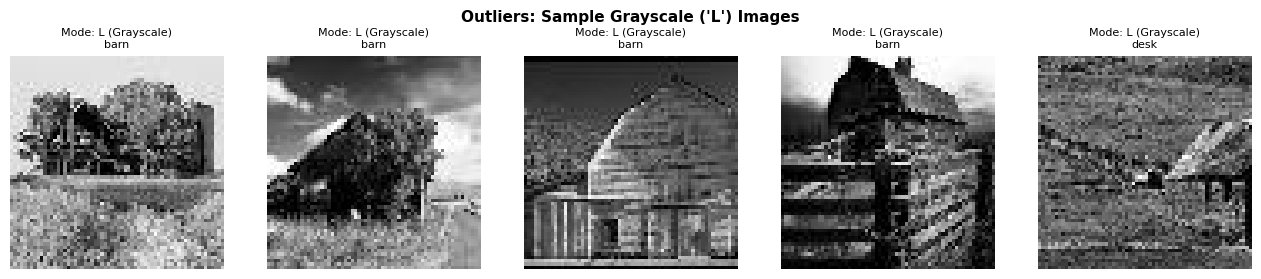

In [10]:
# 1. Count color modes across the dataset
if 'color_mode' not in labels.columns:
    if 'img_info' in globals():
        labels['color_mode'] = [info[1] for info in img_info]
    else:
        labels['color_mode'] = [Image.open(IMAGES_DIR / fn).mode for fn in labels['filename']]

print("Color mode distribution:")
print(labels['color_mode'].value_counts())

# 2. Visualize sample grayscale outlier images
grayscale_samples = labels[labels['color_mode'] == 'L'].head(5)

fig, axes = plt.subplots(1, 5, figsize=(13, 2.8))
for ax, (_, row) in zip(axes, grayscale_samples.iterrows()):
    with Image.open(IMAGES_DIR / row['filename']) as img:
        ax.imshow(img.convert('RGB'))
    ax.set_title(f"Mode: L (Grayscale)\n{row['description'][:15]}", fontsize=8)
    ax.axis('off')
fig.suptitle("Outliers: Sample Grayscale ('L') Images", fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

### 1.9.2 Statistical Pixel Intensity Outliers (Brightness and Contrast)

Images with extreme lighting (average pixel brightness near 0 or 255) or virtually zero contrast (standard deviation near 0) are visual outliers. These images convey minimal discriminative features and can destabilize gradient updates. Here we compute brightness and contrast per image, check for blank/flat images, and visualize the most extreme outliers.

--- Brightness Summary (0-255) ---
count    60000.00
mean       112.52
std         32.94
min          6.64
25%         91.88
50%        111.58
75%        131.01
max        248.93
Name: brightness, dtype: float64

--- Contrast Summary (0-255) ---
count    60000.00
mean        60.21
std         14.57
min          6.10
25%         50.60
50%         60.56
75%         69.94
max        116.00
Name: contrast, dtype: float64

Completely flat/blank images (contrast < 1): 0


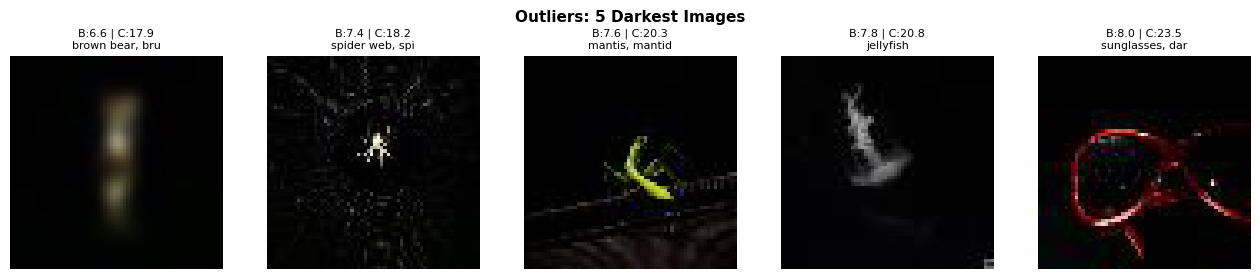

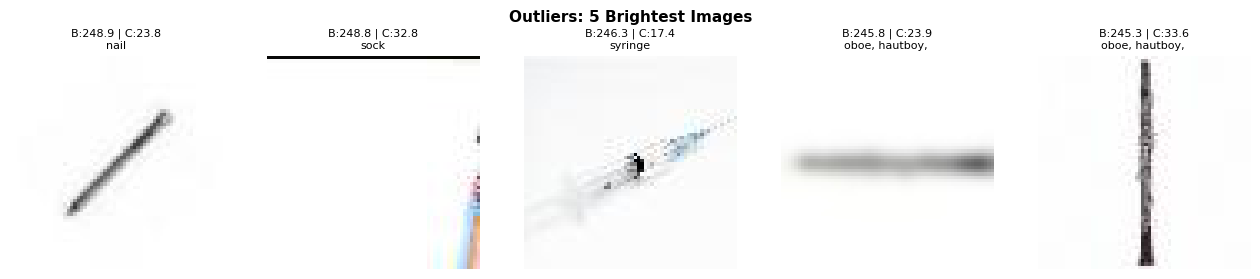

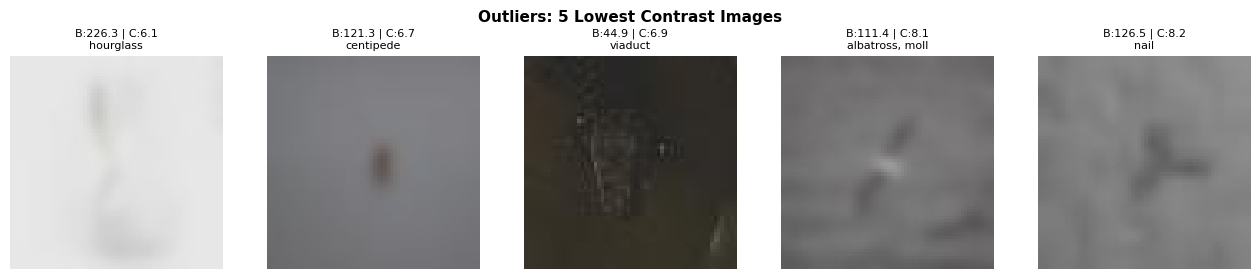

In [11]:
# 1. Calculate brightness and contrast for each image
def get_image_stats(filename):
    try:
        with Image.open(IMAGES_DIR / filename) as img:
            arr = np.array(img.convert('RGB'), dtype=np.float32)
            return arr.mean(), arr.std()
    except Exception:
        return None, None

with ThreadPoolExecutor(max_workers=16) as pool:
    stats = list(pool.map(get_image_stats, labels['filename']))

labels['brightness'] = [s[0] for s in stats]
labels['contrast'] = [s[1] for s in stats]

# 2. Summary statistics and flat image audit
print("--- Brightness Summary (0-255) ---")
print(labels['brightness'].describe().round(2))
print("\n--- Contrast Summary (0-255) ---")
print(labels['contrast'].describe().round(2))

flat_images = labels[labels['contrast'] < 1.0]
print(f"\nCompletely flat/blank images (contrast < 1): {len(flat_images)}")

# 3. Visualize top 5 extreme outliers for each category
def show_outliers(df_subset, title):
    fig, axes = plt.subplots(1, len(df_subset), figsize=(13, 2.8))
    for ax, (_, row) in zip(axes, df_subset.iterrows()):
        with Image.open(IMAGES_DIR / row['filename']) as img:
            ax.imshow(img.convert('RGB'))
        ax.set_title(f"B:{row['brightness']:.1f} | C:{row['contrast']:.1f}\n{row['description'][:15]}", fontsize=8)
        ax.axis('off')
    fig.suptitle(title, fontsize=11, fontweight='bold')
    plt.tight_layout()
    plt.show()

show_outliers(labels.nsmallest(5, 'brightness'), "Outliers: 5 Darkest Images")
show_outliers(labels.nlargest(5, 'brightness'), "Outliers: 5 Brightest Images")
show_outliers(labels.nsmallest(5, 'contrast'), "Outliers: 5 Lowest Contrast Images")

## 1.10 Summary of EDA findings and preprocessing decisions

Summary of verified findings:

1. **Completeness & Integrity:** All 60,000 label rows map to valid files on disk with zero missing, unlabeled, or corrupted files. All images have uniform dimensions of 64x64 pixels.
2. **Color Channels:** 59,194 images are standard 3-channel RGB, but **806 images are 1-channel Grayscale (`'L'`)**.
   - *Preprocessing rule:* Explicitly call `.convert('RGB')` on every image during data loading to ensure consistent tensor shapes.
3. **Class Imbalance:** Class representation ranges from 108 to 549 images per class (imbalance ratio of 5.08x).
   - *Partitioning rule:* Use **stratified splitting** across train, validation, and test sets.
4. **Label Inconsistencies & Duplicates:** Exactly 12 duplicate image instances (6 pairs) exist, and all 6 pairs have **conflicting class labels** (e.g., *parking meter* vs *orange*, *fur coat* vs *CD player*, *spiny lobster* vs *American lobster*).
   - *Data cleaning rule:* Exclude these 12 conflicting samples to eliminate contradictory supervision and avoid train-test leakage.
5. **Visual Outliers (Brightness & Contrast):** Pixel distributions show natural photographic variations without corrupted or completely flat (contrast < 1) blank images.


# 2. Data preparation and image preprocessing